# Does the KV replacement policy matter? Bounds, recompute, and admission order

**Question.** The project started from the hypothesis that an *oracle* KV replacement policy (Belady: evict the
conversation whose tool returns furthest in the future, reload just in time) lowers p99 inter-turn TTFT for agentic
workloads. This notebook tests that claim as hard as we can, separately from admission scheduling.

**TL;DR**

| # | Finding | Evidence |
|---|---|---|
| 1 | **Which KV you evict does not matter.** From a deliberately bad policy (anti-oracle) to a free-transfer upper bound, p99 TTFT moves ≤3 s and mean E2E ≤0.25%. | Fig 1, Table 1 (21 paired workloads, 2 traces, 48/64 GB) |
| 2 | **Having a CPU tier does matter.** Dropping evicted KV and re-prefilling it (vLLM recompute) is +75–137% E2E and ~2× p99 TTFT. | Fig 1, Table 1 |
| 3 | **Admission order sets the tail.** Index order + 300K cap (previous best) has 3–8× higher p99 TTFT than FIFO. | Fig 1, Fig 2 |
| 4 | **Caps lose on E2E under FIFO** (+6% / +12% / +16% at 48 / 64 / 128 GB): faster decode, more queueing. | Table 3, Fig 2 |
| 5 | **Under heavy overload FIFO costs mean E2E** (BrowseComp+ 48 GB: 2031 vs 1855 s for index order) while removing the tail. | Fig 2 (BrowseComp+) |
| 6 | **Our scheduler additions (backfill + guard) are marginal** vs FIFO + LRU: −1.4% E2E, −19% p50 TTFT, but +12% p99 TTFT at 48 GB. | Table 2 |

**Setup.** Oracle-vidur simulator, calibrated H100 cost model and PCIe link (46 GiB/s); 40 agent conversations,
Poisson arrivals λ = 0.15/s; **21 held-out workloads** (seeds 1–20 + 42; a seed picks 40 traces and the arrival times).
Traces: **SWE-bench** (exgentic, peak context median 34K tokens) and **BrowseComp+** (exgentic, median 117K tokens).
Every comparison is **paired**: all policies see the same 21 workloads.

**Two separate decisions:**

| | Prioritization: who gets into HBM first | Eviction: whose KV leaves HBM |
|---|---|---|
| Checkpoint 1 (previous best) | conversation-index order, hard 300K-token cap | Belady oracle + JIT reload |
| FIFO + X | first-come-first-served by turn ready time, no cap | X = LRU / Belady / anti-oracle / free transfers / drop & recompute |
| Ours | ≈FIFO (age guard D = 1 s) + backfill + soft cap + headroom guard | queue-aware Belady + prefetch |

**Replacement variants (eviction only; admission = FIFO for all):**
* **Anti-oracle (worst case)** – evicts what is needed *soonest* (queued turns, then soonest tool return). Adversarial lower anchor.
* **LRU** – least recently used blocks; reactive reload. vLLM-like.
* **Belady oracle** – the original proposal.
* **Free transfers (best case / bound)** – FIFO + LRU with PCIe ×10⁴. A replacement policy can only save transfer cost,
  so *no policy can beat this run*. Used only as a bound; every real result uses the calibrated link.
* **Drop & recompute** – evicted KV is discarded (no CPU tier) and re-prefilled at the next admission.

All raw numbers come from `results/coop*/summary.json`, produced by `sim/run_coop_experiments.py`
(experiments `fifo`, `fifolru`, `fix`, `bcp`, `bound`, `bcpbound`, `anti`, `bcpanti`, `drop`, `bcpdrop`, `hbm128`).


In [1]:
import json, math, os, statistics as st
import numpy as np
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

S = {}
# order matters: coop_drop_long (40000 s horizon) supersedes the truncated BrowseComp+ recompute runs
for d in ["results/coop", "results/coop_hbm128", "results/coop_bcp", "results/coop_bound",
          "results/coop_anti", "results/coop_drop", "results/coop_drop_long"]:
    p = os.path.join(d, "summary.json")
    if os.path.exists(p):
        S.update(json.load(open(p)))
SEEDS = list(range(1, 21)) + [42]
T975, T95 = 2.086, 1.725          # Student t, df = 20

def runs(key, h):
    return [S[f"{key}|{h}|0.15|{s}"] for s in SEEDS]
def g(x, k):
    return x[k] if k in x else x["coop_metrics"][k]
def mean(key, h, k):
    return st.mean(g(x, k) for x in runs(key, h))

KEYS = {   # policy -> result key, per trace
    "swe": dict(cp1="fix|Cap Oracle (300K)", idx="fix|Uncapped Oracle", drop="drop|FIFO + drop & recompute",
                anti="anti|ADVERSARIAL FIFO + anti-oracle", lru="fifolru|FIFO + LRU, no cap", bel="fifo|FIFO, no cap",
                qa="fix|turn-FIFO, no cap", free="bound|BOUND FIFO + LRU, free reload",
                cap300="fifo|FIFO + cap 300K", cap12="fifo|FIFO + B_cap=12", ours="fix|Coop + guard"),
    "bcp": dict(cp1="bcp|Cap Oracle (300K)", idx="bcp|Uncapped Oracle", drop="bcpdrop|FIFO + drop & recompute",
                anti="bcpanti|ADVERSARIAL FIFO + anti-oracle", lru="bcp|FIFO + LRU, no cap", bel="bcp|FIFO, no cap",
                free="bcpbound|BOUND FIFO + LRU, free reload",
                cap300="bcp|FIFO + cap 300K", cap12="bcp|FIFO + B_cap=12", ours="bcp|Coop + guard"),
}
SETTINGS = [("SWE-bench\n48 GB", "swe", 48), ("SWE-bench\n64 GB", "swe", 64),
            ("BrowseComp+\n48 GB", "bcp", 48), ("BrowseComp+\n64 GB", "bcp", 64)]
# sanity: every run used in this notebook finished all 40 conversations
bad = [(tr, h, p) for _, tr, h in SETTINGS for p, k in KEYS[tr].items() if any(x["done"] < 40 for x in runs(k, h))]
print("runs with unfinished conversations:", bad or "none")


runs with unfinished conversations: none


## 1. Replacement policy vs. CPU tier vs. admission order

All bars except *Checkpoint 1* use FIFO admission, so the blue bars and the orange bar differ **only in eviction**.


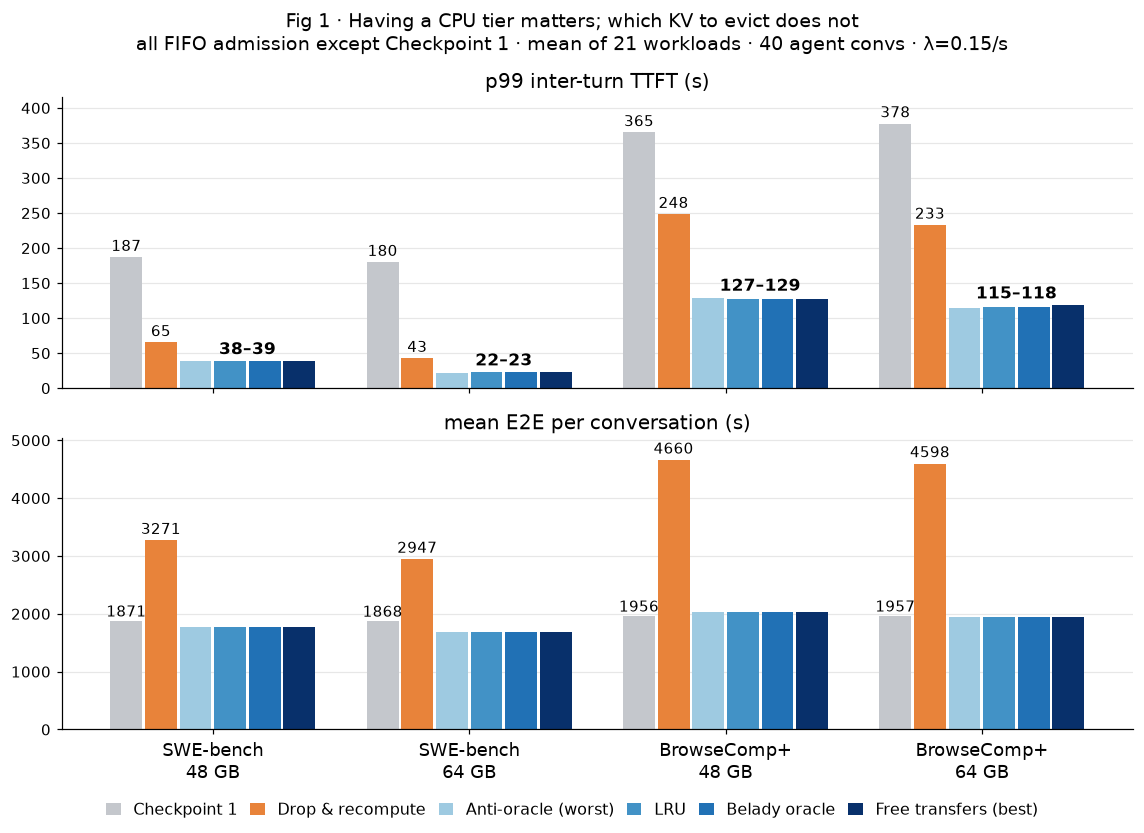

In [2]:
POL = [("cp1", "Checkpoint 1", "#c4c7cc"), ("drop", "Drop & recompute", "#e8833a"),
       ("anti", "Anti-oracle (worst)", "#9ecae1"), ("lru", "LRU", "#4292c6"),
       ("bel", "Belady oracle", "#2171b5"), ("free", "Free transfers (best)", "#08306b")]
fig, axs = plt.subplots(2, 1, figsize=(10.5, 7.6), sharex=True)
x = np.arange(len(SETTINGS)); w = 0.135
for ax, (k, t) in zip(axs, [("ttft_p99", "p99 inter-turn TTFT (s)"), ("mean_e2e_s", "mean E2E per conversation (s)")]):
    top = 0
    for j, (p, lab, c) in enumerate(POL):
        v = [mean(KEYS[tr][p], h, k) for _, tr, h in SETTINGS]; top = max(top, max(v))
        ax.bar(x + (j - 2.5) * w, v, w * 0.92, color=c, label=lab)
        if p in ("cp1", "drop"):
            for xi, vi in zip(x + (j - 2.5) * w, v):
                ax.text(xi, vi + top * 0.01, f"{vi:.0f}", ha="center", va="bottom", fontsize=10)
    if k == "ttft_p99":
        for i, (_, tr, h) in enumerate(SETTINGS):
            vv = [mean(KEYS[tr][p], h, k) for p, *_ in POL[2:]]
            ax.text(x[i] + w, max(vv) + 4, f"{min(vv):.0f}–{max(vv):.0f}", ha="center", va="bottom",
                    fontsize=11, fontweight="bold")
        ax.set_ylim(0, top * 1.1)
    else:
        ax.set_ylim(0, top * 1.08)
    ax.set_title(t, fontsize=13); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
axs[1].set_xticks(x); axs[1].set_xticklabels([s[0] for s in SETTINGS], fontsize=12)
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=6, frameon=False, fontsize=10.5, handlelength=0.9, columnspacing=0.8)
fig.suptitle("Fig 1 · Having a CPU tier matters; which KV to evict does not\n"
             "all FIFO admission except Checkpoint 1 · mean of 21 workloads · 40 agent convs · λ=0.15/s", fontsize=12.5)
fig.tight_layout(rect=(0, 0.035, 1, 1)); plt.show()


**Reading Fig 1.** In every group the four blue bars (worst case → LRU → Belady → best case) have the same height:
p99 TTFT 38–39 s, 22–23 s, 127–129 s, 115–118 s; E2E identical. So *no* replacement policy can help here, including the
oracle we set out to build. The orange bar (no CPU tier) roughly doubles both metrics. The gray bar (index order + cap)
has 3–8× the p99 TTFT of any FIFO bar.

## 2. Paired statistics (Table 1)

Per-workload % difference vs **FIFO + LRU** on the same workload; mean, 95% CI, and a TOST equivalence verdict
(EQ = 90% CI inside ±5% for p99 metrics, ±1% for E2E).


In [3]:
MARGIN = {"ttft_p99": 5.0, "turn_lat_p99": 5.0, "mean_e2e_s": 1.0}
MET = [("ttft_p99", "p99 TTFT"), ("turn_lat_p99", "p99 turn latency"), ("mean_e2e_s", "mean E2E")]
VARS = [("anti", "anti-oracle (worst)"), ("bel", "Belady oracle"), ("qa", "queue-aware oracle (ours)"),
        ("free", "free transfers (BOUND)"), ("drop", "drop & recompute")]
rows = []
for name, tr, h in SETTINGS:
    ref = runs(KEYS[tr]["lru"], h)
    stall = st.mean(r["state_seconds"]["STALL"] / r["total_requests"] for r in ref)
    print(f"\n{name.replace(chr(10), ' ')}  (FIFO + LRU reload stall {stall:.1f} s/conv)")
    print(f"  {'variant':27s}" + "".join(f"{n:>33s}" for _, n in MET))
    for v, lab in VARS:
        if v not in KEYS[tr]:
            continue
        b = runs(KEYS[tr][v], h); cells = []
        for k, _ in MET:
            d = [100 * (g(y, k) / g(a, k) - 1) for a, y in zip(ref, b)]
            m, se = st.mean(d), st.stdev(d) / math.sqrt(len(d))
            eq = (m - T95 * se > -MARGIN[k]) and (m + T95 * se < MARGIN[k])
            cells.append(f"{m:+7.2f}% [{m - T975 * se:+6.2f},{m + T975 * se:+6.2f}] {'EQ' if eq else '--'}")
        print(f"  {lab:27s}" + "".join(f"{c:>33s}" for c in cells))



SWE-bench 48 GB  (FIFO + LRU reload stall 5.1 s/conv)
  variant                                             p99 TTFT                 p99 turn latency                         mean E2E
  anti-oracle (worst)                +0.33% [ -2.67, +3.33] EQ        -0.65% [ -1.69, +0.39] EQ        -0.01% [ -0.18, +0.16] EQ
  Belady oracle                      +1.61% [ -1.94, +5.16] EQ        -0.34% [ -1.38, +0.70] EQ        +0.04% [ -0.16, +0.24] EQ
  queue-aware oracle (ours)          +0.96% [ -3.02, +4.95] EQ        +0.92% [ -0.07, +1.91] EQ        +0.16% [ -0.02, +0.35] EQ
  free transfers (BOUND)             +1.10% [ -2.45, +4.64] EQ        -0.76% [ -1.93, +0.41] EQ        +0.02% [ -0.11, +0.16] EQ
  drop & recompute                  +75.81% [+66.48,+85.14] --       +80.70% [+74.38,+87.02] --       +84.33% [+81.35,+87.31] --

SWE-bench 64 GB  (FIFO + LRU reload stall 4.7 s/conv)
  variant                                             p99 TTFT                 p99 turn latency                     

**Why the spread is so small.** A replacement policy only decides *which* KV moves to CPU and *when* it comes back.
Those transfers (~0.1 s per reload on SWE-bench, ~0.3 s on BrowseComp+) overlap with tool calls and with other
conversations decoding, so the GPU never waits on them and throughput is unchanged; with free transfers the result is
the same. On BrowseComp+ HBM holds only ~3 conversations at peak, so almost every non-running conversation is evicted
regardless of policy (anti-oracle and LRU evict the same ~9.4 TB). Even the "reload stall" state is mostly waiting for
HBM space to restore into, not PCIe time: free transfers only cut it 5.1 → 4.2 s/conv (SWE 48 GB), 7.2 → 2.6 s/conv (BrowseComp+ 48 GB).

**Scope.** Holds when evicted KV goes to a CPU tier with ample capacity. Without a CPU tier (drop & recompute) the
eviction mechanism matters a lot. Limited CPU capacity (where *which* KV to keep in CPU matters) is not tested.

## 3. Prioritization ladder: time breakdown and HBM residency (Fig 2)

Rows add one change at a time. Middle panel: where a conversation's time goes (bar length = mean E2E). Right panel:
average number of concurrent conversations by where their KV lives (same metric as `master_validation`), plus the
admission queue (hatched).


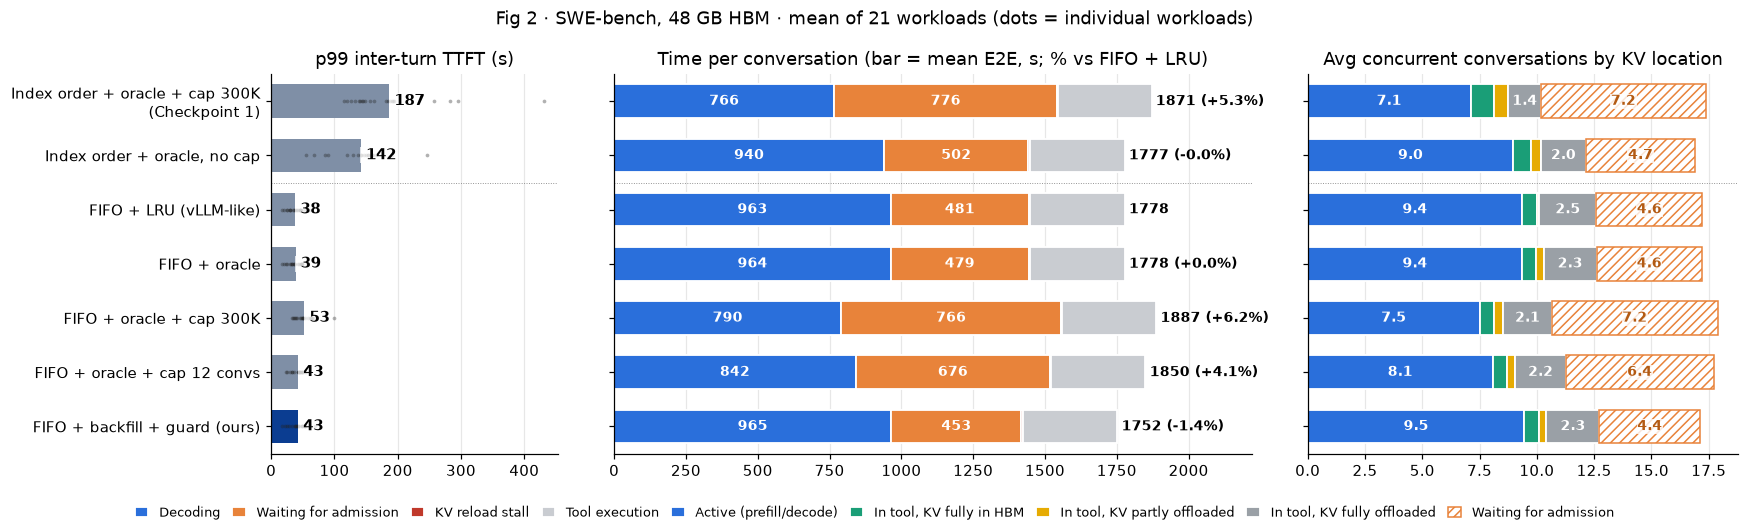

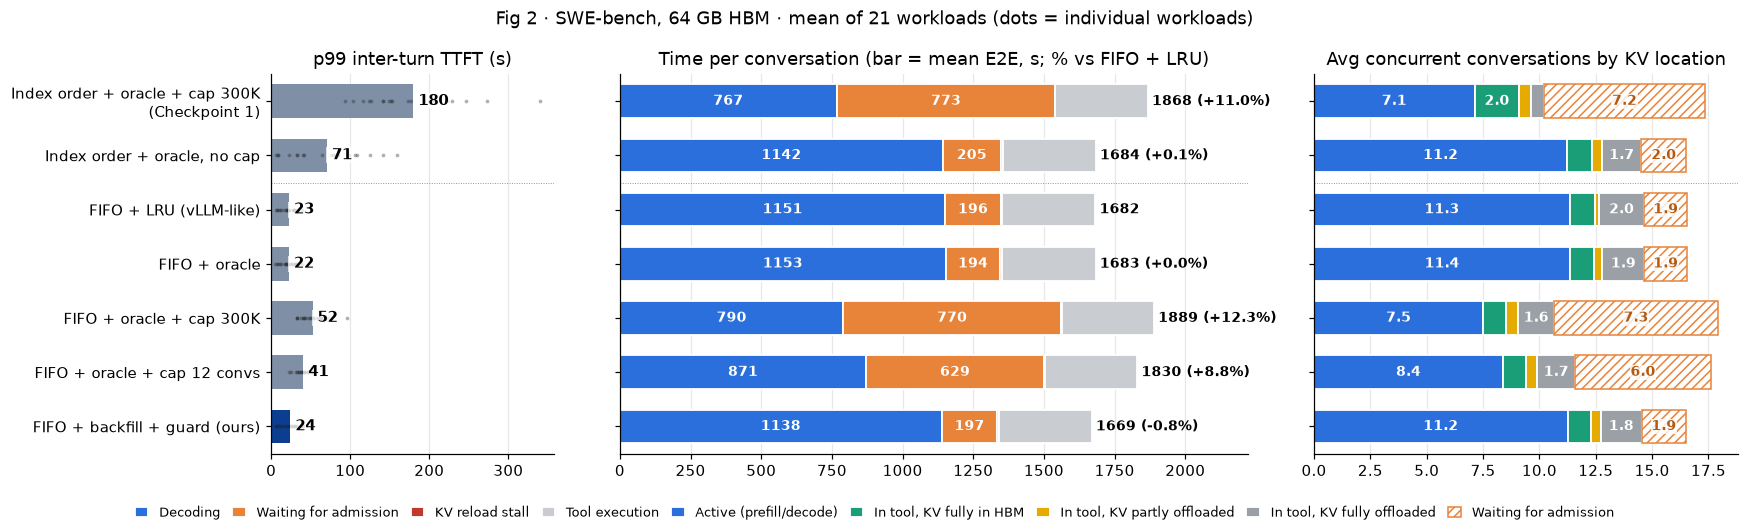

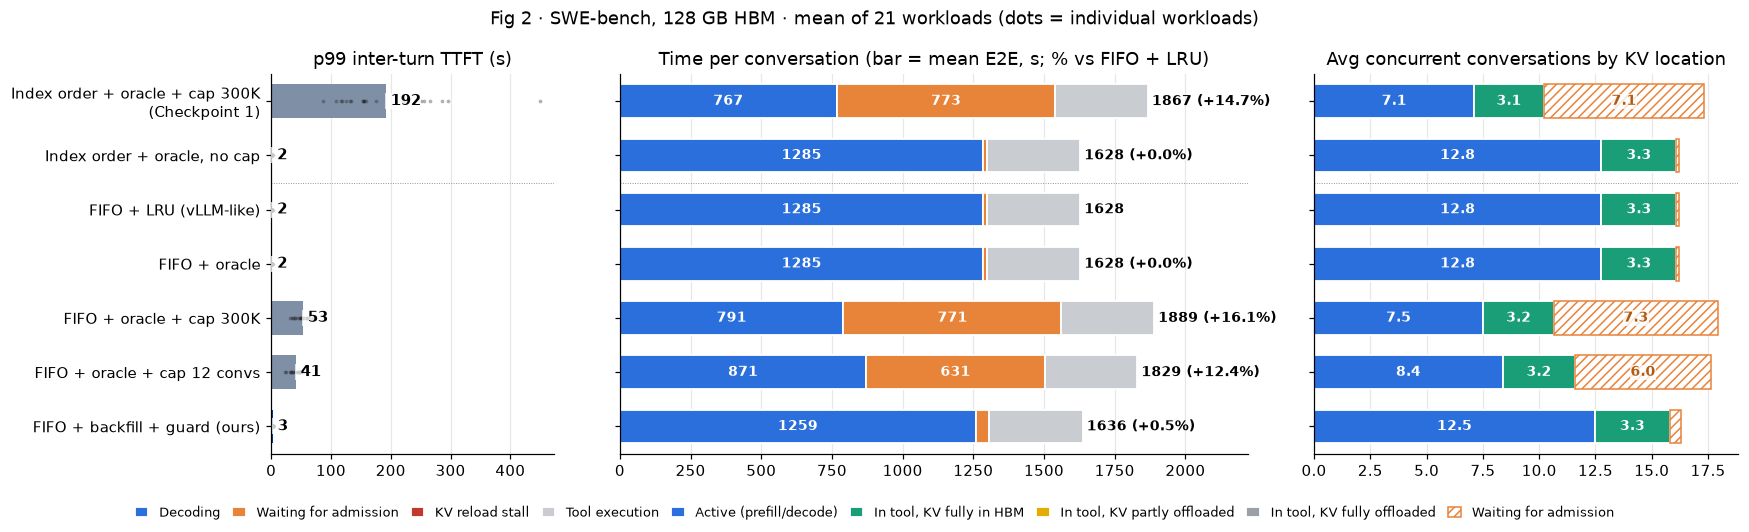

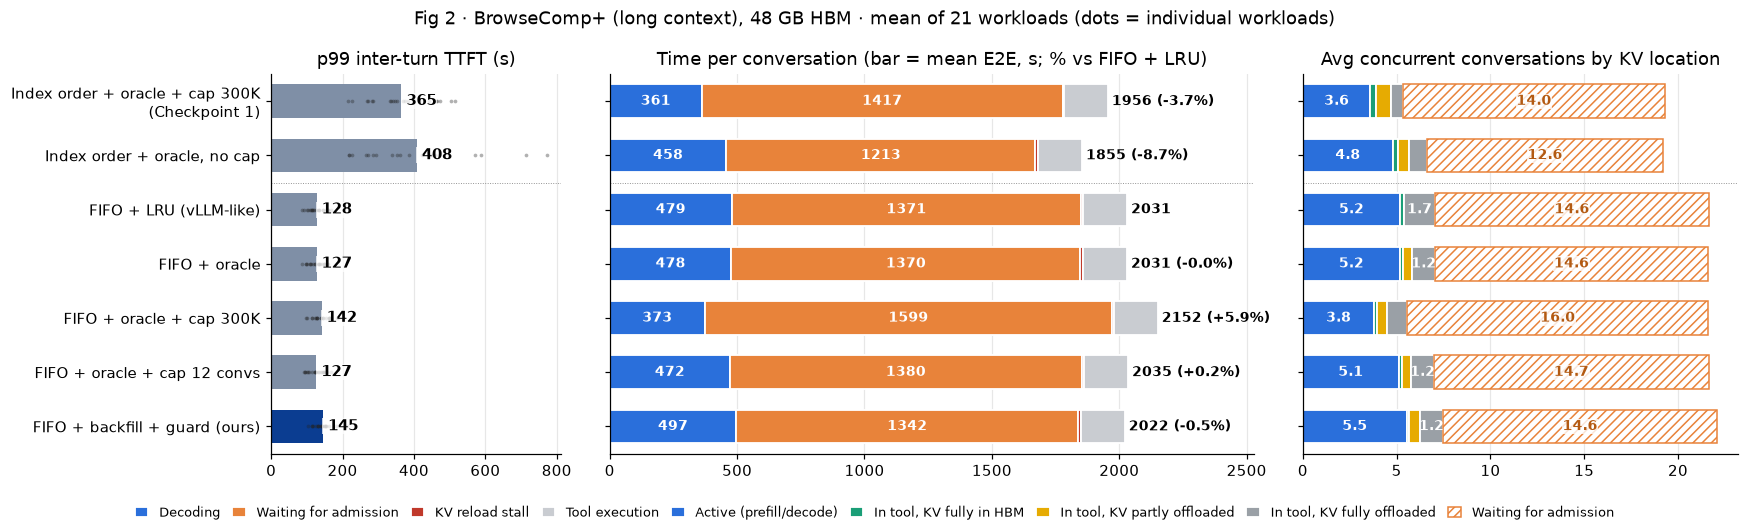

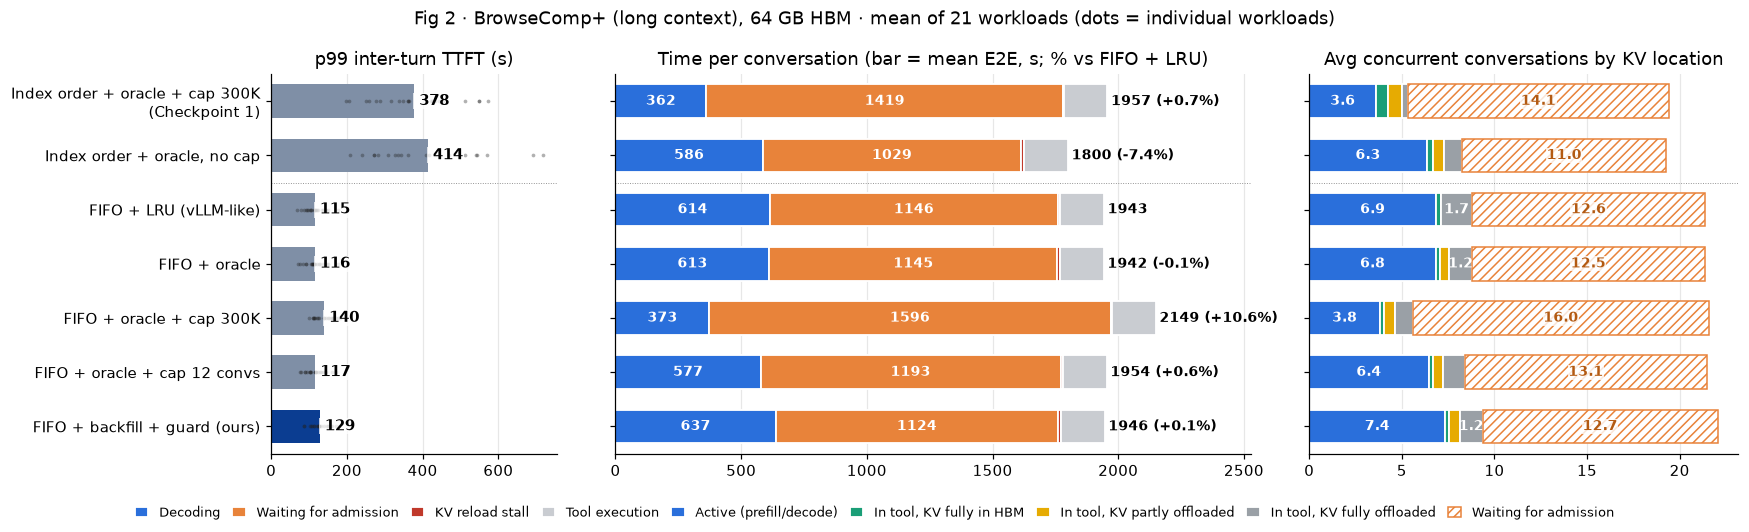

In [4]:
ROWS = [("Index order + oracle + cap 300K\n(Checkpoint 1)", "cp1"), ("Index order + oracle, no cap", "idx"),
        ("FIFO + LRU (vLLM-like)", "lru"), ("FIFO + oracle", "bel"), ("FIFO + oracle + cap 300K", "cap300"),
        ("FIFO + oracle + cap 12 convs", "cap12"), ("FIFO + backfill + guard (ours)", "ours")]
KEY128 = dict(cp1="hbm128|Cap Oracle (300K)", idx="hbm128|Uncapped Oracle", lru="hbm128|FIFO + LRU, no cap",
              bel="hbm128|FIFO, no cap", cap300="hbm128|FIFO + cap 300K", cap12="hbm128|FIFO + B_cap=12",
              ours="hbm128|Coop + guard")
TIME = [("DECODE", "Decoding", "#2a6fdb"), ("WAITING", "Waiting for admission", "#e8833a"),
        ("STALL", "KV reload stall", "#c0392b"), ("TOOL", "Tool execution", "#c9ccd1")]
RES = [("active_compute", "Active (prefill/decode)", "#2a6fdb"), ("tool_full_hbm", "In tool, KV fully in HBM", "#1a9e77"),
       ("tool_partial_hbm", "In tool, KV partly offloaded", "#e6ab02"), ("tool_offloaded_only", "In tool, KV fully offloaded", "#9aa0a6")]

def ladder(tr, h):
    keys = KEY128 if h == 128 else KEYS[tr]
    n = len(ROWS); ref = st.mean(r["mean_e2e_s"] for r in runs(keys["lru"], h))
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True, gridspec_kw=dict(width_ratios=[0.9, 2.0, 1.35]))
    for i, (lab, p) in enumerate(ROWS):
        rs = runs(keys[p], h)
        v = [g(r, "ttft_p99") for r in rs]; m = st.mean(v)
        a1.barh(i, m, color="#0b3d91" if p == "ours" else "#7f8fa6", height=0.62)
        a1.scatter(v, [i] * len(v), s=6, color="#222", alpha=0.35, zorder=3, linewidths=0)
        a1.text(m, i, f" {m:.0f}", va="center", fontsize=9.5, fontweight="bold", zorder=4,
                bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.75))
        vals = {k: st.mean(r["state_seconds"].get(k, 0) / r["total_requests"] for r in rs) for k, *_ in TIME}
        left = 0
        for k, name, c in TIME:
            a2.barh(i, vals[k], left=left, color=c, height=0.62, edgecolor="white", linewidth=1.2, label=name if i == 0 else None)
            if k in ("DECODE", "WAITING") and vals[k] > 120:
                a2.text(left + vals[k] / 2, i, f"{vals[k]:.0f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
            left += vals[k]
        e2e = st.mean(r["mean_e2e_s"] for r in rs)
        a2.text(left + 15, i, f"{e2e:.0f}" + ("" if p == "lru" else f" ({100 * (e2e / ref - 1):+.1f}%)"), va="center", fontsize=9, fontweight="bold")
        rv = {k: st.mean(r["residency_seconds"][k] / max(1e-9, r["residency_seconds"]["active_wall"]) for r in rs) for k, *_ in RES}
        wq = st.mean(r["state_seconds"]["WAITING"] / max(1e-9, r["residency_seconds"]["active_wall"]) for r in rs)
        left = 0
        for k, name, c in RES:
            a3.barh(i, rv[k], left=left, color=c, height=0.62, edgecolor="white", linewidth=1.2, label=name if i == 0 else None)
            if rv[k] >= 1.2:
                a3.text(left + rv[k] / 2, i, f"{rv[k]:.1f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
            left += rv[k]
        a3.barh(i, wq, left=left, color="white", height=0.62, edgecolor="#e8833a", hatch="////", linewidth=1.0,
                label="Waiting for admission" if i == 0 else None)
        if wq >= 1.2:
            a3.text(left + wq / 2, i, f"{wq:.1f}", ha="center", va="center", fontsize=9, color="#b35a12", fontweight="bold",
                    bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.8))
    a1.set_title("p99 inter-turn TTFT (s)"); a2.set_title("Time per conversation (bar = mean E2E, s; % vs FIFO + LRU)")
    a3.set_title("Avg concurrent conversations by KV location")
    for ax in (a1, a2, a3):
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True); ax.axhline(1.5, color="#888", lw=0.6, ls=":")
    a2.set_xlim(0, a2.get_xlim()[1] * 1.12)
    a1.set_yticks(range(n)); a1.set_yticklabels([r[0] for r in ROWS], fontsize=10); a1.set_ylim(n - 0.5, -0.5)
    h2, l2 = a2.get_legend_handles_labels(); h3, l3 = a3.get_legend_handles_labels()
    fig.legend(h2 + h3, l2 + l3, loc="lower center", ncol=9, frameon=False, fontsize=8.8, handlelength=1.0, columnspacing=0.9)
    wl = "BrowseComp+ (long context)" if tr == "bcp" else "SWE-bench"
    fig.suptitle(f"Fig 2 · {wl}, {h} GB HBM · mean of 21 workloads (dots = individual workloads)", fontsize=11.5)
    fig.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

for tr, h in [("swe", 48), ("swe", 64), ("swe", 128), ("bcp", 48), ("bcp", 64)]:
    ladder(tr, h)


**Reading Fig 2.**
* *Index order → FIFO* is the big step for the tail (SWE 48 GB: 187 → 38 s p99 TTFT). Under index order a late
  conversation's turn queues behind every earlier conversation on every turn.
* *Caps* shrink the active set (≈9.4 → 7.5 conversations at 48 GB), so decoding is faster, but the queue grows more
  (4.6 → 7.2 waiting). At 128 GB nothing is ever evicted and nothing waits under FIFO, so a fixed 300K cap is pure loss.
* *LRU vs oracle* rows are indistinguishable in every panel, including residency.
* BrowseComp+ is heavily overloaded (~1370 s waiting vs ~480 s decoding per conversation). There FIFO removes the tail
  (408 → 128 s) but raises mean E2E vs index order (+9.5% at 48 GB): index order keeps finishing conversations it already
  started, which lowers mean completion time at the cost of starving late ones.

## 4. Our scheduler additions vs FIFO + LRU (Table 2)


In [5]:
MET2 = [("ttft_p99", "p99 TTFT"), ("ttft_p50", "p50 TTFT"), ("turn_lat_p99", "p99 turn lat"),
        ("mean_e2e_s", "mean E2E"), ("preemptions", "preemptions/run")]
for h in (48, 64, 128):
    A = runs(KEY128["lru"] if h == 128 else KEYS["swe"]["lru"], h)
    B = runs(KEY128["ours"] if h == 128 else KEYS["swe"]["ours"], h)
    print(f"\nSWE-bench {h} GB      FIFO+LRU      ours     change   ours better on")
    for k, n in MET2:
        a, b = st.mean(g(x, k) for x in A), st.mean(g(x, k) for x in B)
        w = sum(g(y, k) < g(x, k) for x, y in zip(A, B))
        print(f"  {n:16s} {a:9.1f} {b:9.1f} {100 * (b / a - 1) if a else 0:+8.1f}%   {w:2d}/21")



SWE-bench 48 GB      FIFO+LRU      ours     change   ours better on
  p99 TTFT              38.1      42.8    +12.1%    0/21
  p50 TTFT              10.1       8.2    -19.2%   21/21
  p99 turn lat         165.5     165.8     +0.2%   10/21
  mean E2E            1777.6    1751.9     -1.4%   21/21
  preemptions/run        8.9       0.0   -100.0%   21/21

SWE-bench 64 GB      FIFO+LRU      ours     change   ours better on
  p99 TTFT              22.5      24.2     +7.6%    7/21
  p50 TTFT               2.7       2.3    -13.4%   12/21
  p99 turn lat         181.7     180.8     -0.5%   16/21
  mean E2E            1682.0    1669.2     -0.8%   16/21
  preemptions/run        6.3       0.0    -99.2%   19/21

SWE-bench 128 GB      FIFO+LRU      ours     change   ours better on
  p99 TTFT               1.6       2.6    +59.3%    0/21
  p50 TTFT               0.4       1.4   +228.0%    0/21
  p99 turn lat         199.1     196.1     -1.5%   21/21
  mean E2E            1627.6    1636.4     +0.5%   

Backfill (smaller turns go ahead when the head of the queue does not fit) is where the E2E and p50 gain comes from;
the guard removes preemptions, which cost FIFO only ~0.4 s/conv. Backfill lets small turns jump ahead of large ones,
which is why p99 TTFT gets slightly *worse*; at 128 GB the soft cap only adds delay. **The honest headline is FIFO + LRU.**

## 5. Caps under FIFO across HBM sizes (Table 3)


In [6]:
print(f"{'SWE-bench':12s} {'policy':22s} {'p99 TTFT':>9s} {'p99 turn':>9s} {'mean E2E':>9s} {'vs no cap':>10s} {'worse on':>9s}")
for h in (48, 64, 128):
    K = KEY128 if h == 128 else KEYS["swe"]
    A = runs(K["bel"], h)
    for p, lab in [("bel", "FIFO, no cap"), ("cap300", "FIFO + cap 300K"), ("cap12", "FIFO + cap 12 convs")]:
        B = runs(K[p], h)
        e = st.mean(x["mean_e2e_s"] for x in B); e0 = st.mean(x["mean_e2e_s"] for x in A)
        worse = sum(y["mean_e2e_s"] > x["mean_e2e_s"] for x, y in zip(A, B))
        print(f"{h:>4d} GB      {lab:22s} {mean(K[p], h, 'ttft_p99'):9.1f} {mean(K[p], h, 'turn_lat_p99'):9.1f} {e:9.0f} "
              f"{100 * (e / e0 - 1):+9.1f}% {'' if p == 'bel' else f'{worse:2d}/21':>9s}")


SWE-bench    policy                  p99 TTFT  p99 turn  mean E2E  vs no cap  worse on
  48 GB      FIFO, no cap                38.8     165.0      1778      +0.0%          
  48 GB      FIFO + cap 300K             52.7     153.4      1887      +6.2%     21/21
  48 GB      FIFO + cap 12 convs         42.9     160.1      1850      +4.1%     21/21
  64 GB      FIFO, no cap                22.4     181.8      1683      +0.0%          
  64 GB      FIFO + cap 300K             52.4     153.7      1889     +12.3%     21/21
  64 GB      FIFO + cap 12 convs         40.8     161.6      1830      +8.8%     21/21
 128 GB      FIFO, no cap                 1.6     199.1      1628      +0.0%          
 128 GB      FIFO + cap 300K             52.9     153.9      1889     +16.1%     21/21
 128 GB      FIFO + cap 12 convs         41.1     161.5      1829     +12.4%     21/21


A cap cuts decode time (e.g. 964 → 790 s/conv at 48 GB) but adds more admission waiting, so E2E is worse on every
workload, and more so as HBM grows (a fixed cap wastes more memory). The one metric a cap improves is p99 turn latency
(no preemptions, smaller batches).

## Caveats
* Simulator only (calibrated cost model + PCIe link); 40 conversations per run, one arrival rate (λ = 0.15/s).
* The free-transfer and anti-oracle runs are **bounds**, not proposals; the hardware model is unchanged for every real policy.
* Drop & recompute is implemented as LRU with evicted blocks discarded (vLLM prefix-cache style, tail blocks first);
  its BrowseComp+ runs needed a 40 000 s horizon (`results/coop_drop_long`) to finish all conversations — the 8000 s
  runs in `results/coop_drop` for BrowseComp+ are truncated and are not used here.
* Untested regimes where replacement could still matter: limited CPU capacity, shared/contended PCIe, much higher load.

**Reproduce:** `python3.11 sim/run_coop_experiments.py --only fifo fifolru fix hbm128 --out ...` etc. (see the
`EXPERIMENTS` dict; each new experiment group was run into its own `results/coop_*` directory), then
`python3.11 sim/tools/repl_bounds.py` for the bounds table.
